# Задание 2.1. Классификация ЭКГ
Королев Даниил, группа 636-02.

По 140 отсчётам одного сокращения обучил 1D CNN определять класс 0–4.
Ниже показал сигналы, обучение и ошибки на отложенной части.
Условие: https://github.com/AI-is-out-there/check-your-biomed-datascience-skills-review/blob/main/task/task2-1_ecg_supervised_classification.md

Данные находятся в `dataset/task2_1`. Запуск из корня репозитория:
`python your-sollution/task2_1_solution.py`.

In [1]:
%matplotlib inline
from pathlib import Path
import copy
import hashlib
import json
import platform
import random

import matplotlib.pyplot as plt
from IPython import get_ipython
from IPython.display import Markdown, display
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
MAX_EPOCHS = 80
PATIENCE = 15
BATCH_SIZE = 64
CLASSES = np.arange(5)
FEATURES = [f"t_{i:03d}" for i in range(140)]
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
# CPU и фиксированное число потоков упрощают повторение учебного эксперимента.
torch.set_num_threads(2)
torch.use_deterministic_algorithms(True)
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=0.95)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150})
ROOT = Path.cwd()
if not (ROOT / "dataset/task2_1/train.csv").exists():
    ROOT = ROOT.parent
assert (ROOT / "dataset/task2_1/train.csv").exists(), "Запустите код внутри репозитория"
OUT = ROOT / "outputs/task2_1_analysis"
OUT.mkdir(parents=True, exist_ok=True)


def save_figure(filename):
    plt.savefig(OUT / filename, bbox_inches="tight")
    if get_ipython() is not None:
        plt.show()
    plt.close()


print(f"Python {platform.python_version()}, PyTorch {torch.__version__}; устройство: CPU")

Python 3.12.14, PyTorch 2.14.1; устройство: CPU


## Данные и разбиение
Разделил размеченный CSV на обучение, валидацию и внутренний тест в долях
70/15/15, с сохранением долей классов. По валидации выбираю эпоху;
внутренний тест использую после выбора модели.
Отдельный `test_features.csv` нужен для сдачи и не участвует в обучении.

В CSV нет ID пациента или времени записи. По описанию ECG5000 сокращения
получены из одной записи chf07, поэтому такое разбиение не проверяет
качество на новых пациентах.
Источник: https://www.timeseriesclassification.com/description.php?Dataset=ECG5000

In [2]:
train_path = ROOT / "dataset/task2_1/train.csv"
external_path = ROOT / "dataset/task2_1/test_features.csv"
data = pd.read_csv(train_path)
assert data.columns.tolist() == ["heartbeat_id", "prediction", *FEATURES]
assert data["heartbeat_id"].is_unique
assert set(data["prediction"]) == set(CLASSES)
assert not data.isna().any().any()
X = data[FEATURES].to_numpy(dtype=np.float32)
y = data["prediction"].to_numpy(dtype=np.int64)
assert np.isfinite(X).all()
assert not data[FEATURES].duplicated().any(), "Дубликаты надо группировать до разделения"

trainval_idx, test_idx = train_test_split(
    np.arange(len(data)), test_size=0.15, stratify=y, random_state=SEED
)
train_idx, valid_idx = train_test_split(
    trainval_idx, test_size=15 / 85, stratify=y[trainval_idx], random_state=SEED
)
split_indices = {"Обучение": train_idx, "Валидация": valid_idx, "Внутренний тест": test_idx}
assert len(set(train_idx) & set(valid_idx)) == 0
assert len(set(train_idx) & set(test_idx)) == 0
assert len(set(valid_idx) & set(test_idx)) == 0
assert set(np.concatenate(list(split_indices.values()))) == set(range(len(data)))
split_table = pd.DataFrame({name: np.bincount(y[idx], minlength=5)
                            for name, idx in split_indices.items()}, index=CLASSES)
split_table.index.name = "Класс"
assert (split_table > 0).all().all()
display(split_table)
split_table.to_csv(OUT / "class_counts.csv")
split_rows = pd.DataFrame({"heartbeat_id": data["heartbeat_id"], "split": ""})
for name, idx in split_indices.items():
    split_rows.loc[idx, "split"] = name
split_rows.to_csv(OUT / "split_assignment.csv", index=False)
print(f"Строк: {len(data)}; пропусков и точных дубликатов сигналов нет.")

,Обучение,Валидация,Внутренний тест
Класс,,,
0,1635,350,350
1,990,212,212
2,53,12,12
3,109,23,23
4,13,3,3


Строк: 4000; пропусков и точных дубликатов сигналов нет.


## Сигналы и баланс классов
Для каждого класса взял обучающий пример, ближайший к медиане класса,
и показал разброс между 25-м и 75-м процентилями. По оси X — номер отсчёта,
а не секунды: сигналы приведены к длине 140 интерполяцией.
Амплитуда дана в единицах набора.

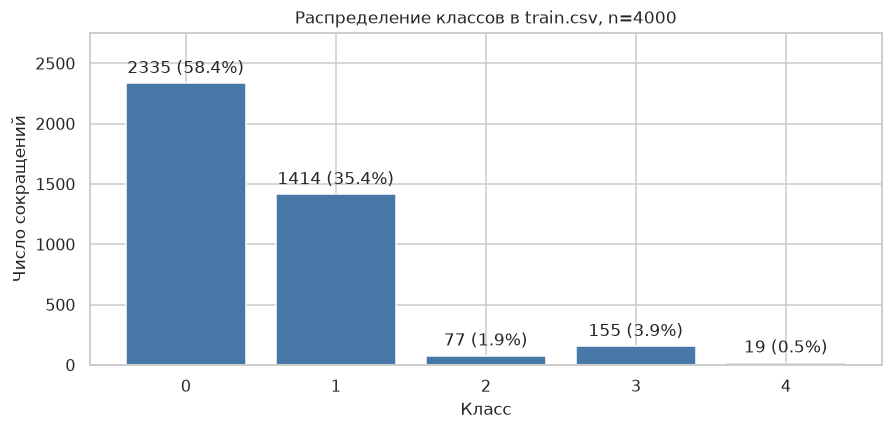

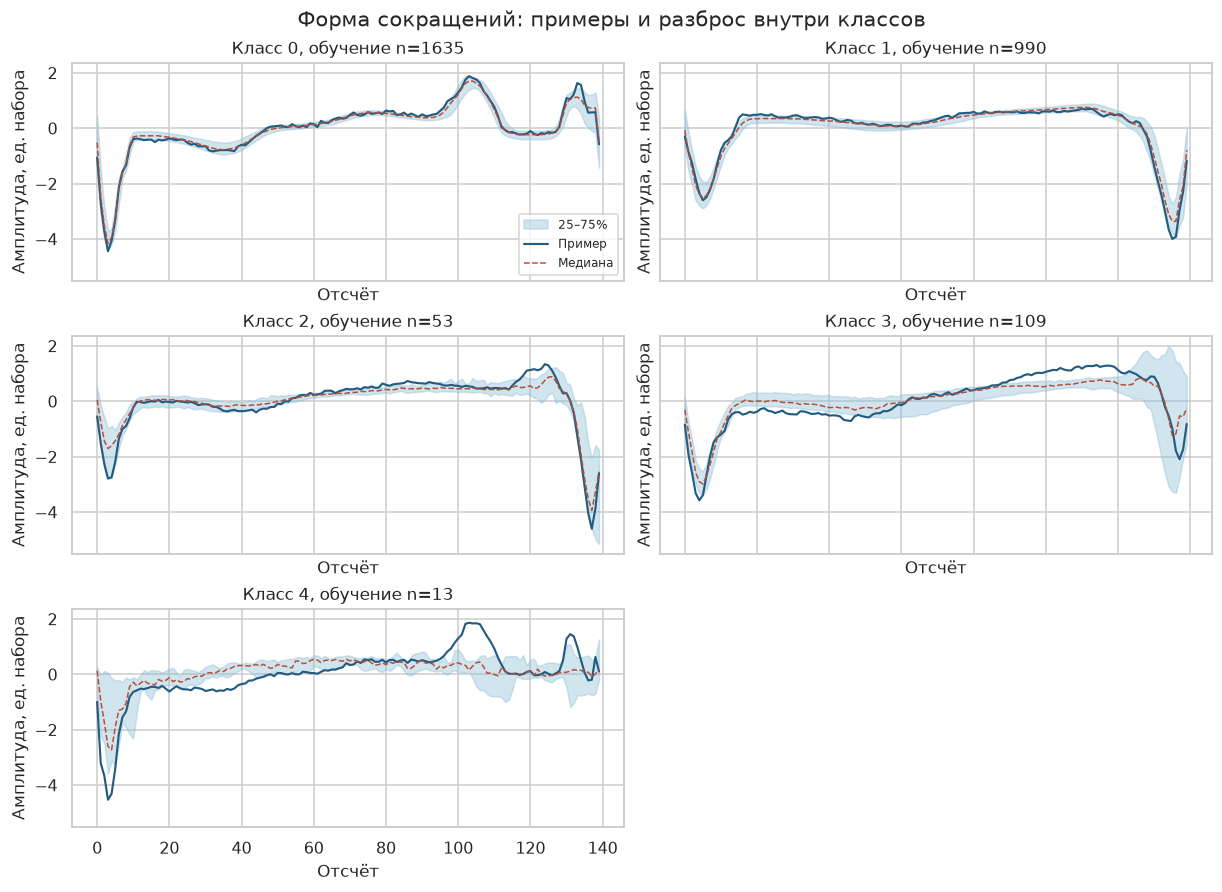

In [3]:
counts = np.bincount(y, minlength=5)
fig, ax = plt.subplots(figsize=(8, 3.8), layout="constrained")
bars = ax.bar([str(c) for c in CLASSES], counts, color="#4878a8")
ax.bar_label(bars, labels=[f"{n} ({n / len(y):.1%})" for n in counts], padding=4)
ax.set(xlabel="Класс", ylabel="Число сокращений", ylim=(0, counts.max() * 1.18),
       title=f"Распределение классов в train.csv, n={len(data)}")
save_figure("class_balance.png")

fig, axes = plt.subplots(3, 2, figsize=(11, 8), sharex=True, sharey=True, layout="constrained")
class_medians = {}
for ax, class_id in zip(axes.flat, CLASSES):
    signals = X[train_idx][y[train_idx] == class_id]
    median = np.median(signals, axis=0)
    class_medians[int(class_id)] = median
    representative = np.argmin(np.mean((signals - median) ** 2, axis=1))
    q25, q75 = np.quantile(signals, [0.25, 0.75], axis=0)
    ax.fill_between(np.arange(140), q25, q75, color="#8cbed6", alpha=0.4, label="25–75%")
    ax.plot(signals[representative], color="#245b80", linewidth=1.4, label="Пример")
    ax.plot(median, "--", color="#b64f39", linewidth=1, label="Медиана")
    ax.set(title=f"Класс {class_id}, обучение n={len(signals)}",
           xlabel="Отсчёт", ylabel="Амплитуда, ед. набора")
axes.flat[0].legend(fontsize=8)
axes.flat[-1].axis("off")
fig.suptitle("Форма сокращений: примеры и разброс внутри классов")
save_figure("representative_signals.png")

## Подготовка и сеть
StandardScaler обучил только на тренировочной части. Для каждого из 140
отсчётов он сохраняет среднее и масштаб. На вход CNN подаю `(batch, 1, 140)`.

В сети три Conv1d-блока на 16, 32 и 64 канала с ReLU. После первых двух —
MaxPool. Усреднение оставляет восемь временных участков, затем идут слои
512→64→5 и Dropout 0.2. Для дисбаланса использовал веса `n / (5 * n_class)`.
Сеть возвращает logits, которые напрямую подаются в CrossEntropyLoss.

In [4]:
scaler = StandardScaler().fit(X[train_idx])
X_train = scaler.transform(X[train_idx]).astype(np.float32)
X_valid = scaler.transform(X[valid_idx]).astype(np.float32)
np.testing.assert_allclose(scaler.mean_, X[train_idx].mean(axis=0, dtype=np.float64))
assert scaler.n_samples_seen_ == len(train_idx)


def make_loader(features, targets, shuffle=False):
    dataset = TensorDataset(torch.from_numpy(features[:, None, :]),
                            torch.tensor(targets, dtype=torch.long))
    generator = torch.Generator().manual_seed(SEED)
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=shuffle,
                      generator=generator, num_workers=0)


class ECGClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv1d(1, 16, 7, padding=3), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(16, 32, 5, padding=2), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(32, 64, 3, padding=1), nn.ReLU(), nn.AdaptiveAvgPool1d(8),
            nn.Flatten(), nn.Linear(64 * 8, 64), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(64, 5),
        )

    def forward(self, x):
        return self.layers(x)


train_loader = make_loader(X_train, y[train_idx], shuffle=True)
train_eval_loader = make_loader(X_train, y[train_idx])
valid_loader = make_loader(X_valid, y[valid_idx])
class_counts = np.bincount(y[train_idx], minlength=5)
class_weights = torch.tensor(len(train_idx) / (5 * class_counts), dtype=torch.float32)
model = ECGClassifier()
criterion = nn.CrossEntropyLoss(weight=class_weights)
criterion_sum = nn.CrossEntropyLoss(weight=class_weights, reduction="sum")
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
display(pd.DataFrame({"Класс": CLASSES, "Число в обучении": class_counts,
                      "Вес в функции потерь": class_weights.numpy().round(3)}))
print(f"Параметров сети: {sum(p.numel() for p in model.parameters()):,}")


def evaluate(loader):
    model.eval()
    loss_sum, weight_sum = 0.0, 0.0
    logits_all, targets_all = [], []
    with torch.inference_mode():
        for features, targets in loader:
            logits = model(features)
            loss_sum += criterion_sum(logits, targets).item()
            weight_sum += class_weights[targets].sum().item()
            logits_all.append(logits)
            targets_all.append(targets)
    targets = torch.cat(targets_all).numpy()
    probabilities = torch.cat(logits_all).softmax(dim=1).numpy()
    predictions = probabilities.argmax(axis=1)
    return {
        "loss": loss_sum / weight_sum,
        "accuracy": accuracy_score(targets, predictions),
        "macro_f1": f1_score(targets, predictions, labels=CLASSES, average="macro", zero_division=0),
        "predictions": predictions, "probabilities": probabilities,
    }

,Класс,Число в обучении,Вес в функции потерь
0,0,1635,0.343
1,1,990,0.566
2,2,53,10.566
3,3,109,5.138
4,4,13,43.077


Параметров сети: 42,085


## Обучение
Задал максимум 80 эпох и остановку после 15 эпох без улучшения macro F1
на валидации. При равном результате оставляю более раннюю эпоху.
Метрики обучения считаю в режиме eval с отключённым Dropout, чтобы
сравнивать их с валидацией. Взвешенную потерю делю на сумму весов примеров.

In [5]:
history_rows = []
best_f1, best_epoch, best_state, wait = -1.0, 0, None, 0
for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    for features, targets in train_loader:
        optimizer.zero_grad(set_to_none=True)
        loss = criterion(model(features), targets)
        assert torch.isfinite(loss), "Нечисловая функция потерь"
        loss.backward()
        optimizer.step()
    train_result, valid_result = evaluate(train_eval_loader), evaluate(valid_loader)
    history_rows.append({"epoch": epoch, "train_loss": train_result["loss"],
                         "valid_loss": valid_result["loss"], "train_f1": train_result["macro_f1"],
                         "valid_f1": valid_result["macro_f1"]})
    if valid_result["macro_f1"] > best_f1:
        best_f1, best_epoch = valid_result["macro_f1"], epoch
        best_state = copy.deepcopy(model.state_dict())
        wait = 0
    else:
        wait += 1
    if epoch == 1 or epoch % 10 == 0 or wait >= PATIENCE:
        print(f"Эпоха {epoch:02d}: train F1={train_result['macro_f1']:.3f}, "
              f"val F1={valid_result['macro_f1']:.3f}, val loss={valid_result['loss']:.3f}")
    if wait >= PATIENCE:
        break
assert best_state is not None
model.load_state_dict(best_state)
history = pd.DataFrame(history_rows)
history.to_csv(OUT / "training_history.csv", index=False)
print(f"Выбрана эпоха {best_epoch}, macro F1 валидации {best_f1:.3f}.")

Эпоха 01: train F1=0.457, val F1=0.396, val loss=1.403


Эпоха 10: train F1=0.620, val F1=0.545, val loss=0.894


Эпоха 20: train F1=0.720, val F1=0.575, val loss=0.951


Эпоха 30: train F1=0.684, val F1=0.545, val loss=1.019


Эпоха 35: train F1=0.670, val F1=0.515, val loss=1.100
Выбрана эпоха 20, macro F1 валидации 0.575.


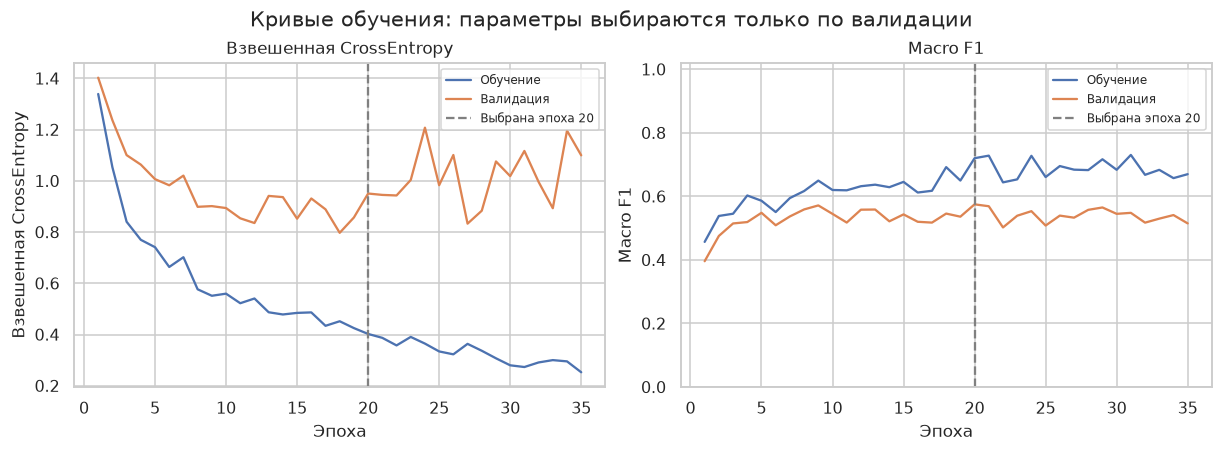

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for ax, metric, ylabel in [(axes[0], "loss", "Взвешенная CrossEntropy"),
                            (axes[1], "f1", "Macro F1")]:
    ax.plot(history["epoch"], history[f"train_{metric}"], label="Обучение")
    ax.plot(history["epoch"], history[f"valid_{metric}"], label="Валидация")
    ax.axvline(best_epoch, linestyle="--", color="gray", label=f"Выбрана эпоха {best_epoch}")
    ax.set(xlabel="Эпоха", ylabel=ylabel, title=ylabel)
    ax.legend(fontsize=8)
axes[1].set_ylim(0, 1.02)
fig.suptitle("Кривые обучения: параметры выбираются только по валидации")
save_figure("training_curves.png")

## Проверка модели
Выбранные веса проверил на внутреннем тесте. Для сравнения добавил ответ
самым частым обучающим классом. Macro F1 учитывает каждый класс поровну,
а Accuracy здесь сильнее зависит от многочисленных классов 0 и 1.

,Accuracy,Macro F1
Модель и выборка,,
"Частый класс, внутренний тест",0.583,0.147
"CNN, валидация",0.898,0.575
"CNN, внутренний тест",0.913,0.582


,precision,recall,f1-score,support
Класс,,,,
0,0.988,0.974,0.981,350
1,0.959,0.873,0.914,212
2,0.370,0.833,0.513,12
3,0.480,0.522,0.500,23
4,0.000,0.000,0.000,3


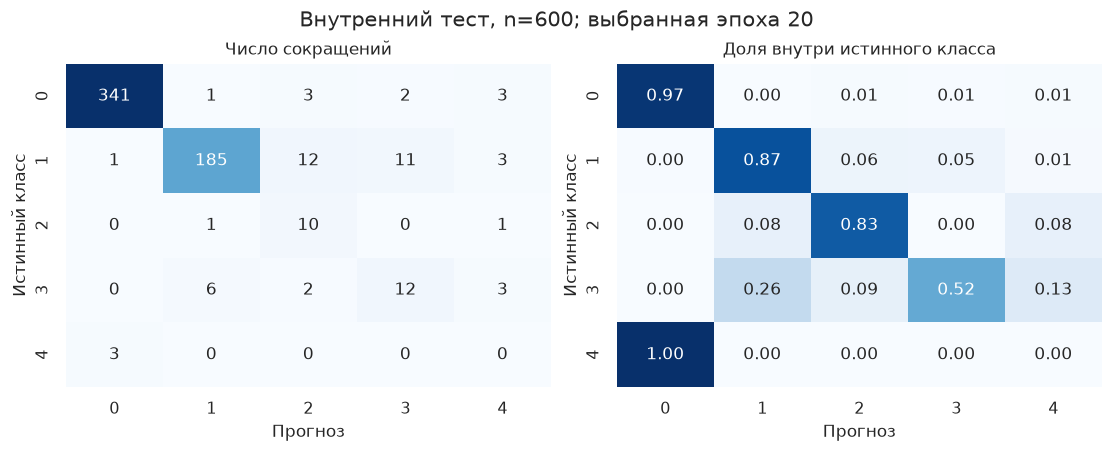

In [7]:
X_test = scaler.transform(X[test_idx]).astype(np.float32)
test_result = evaluate(make_loader(X_test, y[test_idx]))
valid_result = evaluate(valid_loader)
majority = int(np.argmax(class_counts))
baseline_prediction = np.full(len(test_idx), majority)
metrics_table = pd.DataFrame([
    {"Модель и выборка": "Частый класс, внутренний тест",
     "Accuracy": accuracy_score(y[test_idx], baseline_prediction),
     "Macro F1": f1_score(y[test_idx], baseline_prediction, labels=CLASSES, average="macro", zero_division=0)},
    {"Модель и выборка": "CNN, валидация", "Accuracy": valid_result["accuracy"], "Macro F1": valid_result["macro_f1"]},
    {"Модель и выборка": "CNN, внутренний тест", "Accuracy": test_result["accuracy"], "Macro F1": test_result["macro_f1"]},
]).set_index("Модель и выборка")
display(metrics_table.round(3))
metrics_table.to_csv(OUT / "metrics.csv")
class_report = classification_report(y[test_idx], test_result["predictions"], labels=CLASSES,
                                     output_dict=True, zero_division=0)
per_class = pd.DataFrame({str(c): class_report[str(c)] for c in CLASSES}).T
per_class.index.name = "Класс"
per_class["support"] = per_class["support"].astype(int)
display(per_class.round(3))
per_class.to_csv(OUT / "per_class_metrics.csv")
cm = confusion_matrix(y[test_idx], test_result["predictions"], labels=CLASSES)
internal_predictions = pd.DataFrame({"heartbeat_id": data.loc[test_idx, "heartbeat_id"].to_numpy(),
                                     "target": y[test_idx], "prediction": test_result["predictions"]})
for c in CLASSES:
    internal_predictions[f"p_{c}"] = test_result["probabilities"][:, c]
internal_predictions.to_csv(OUT / "internal_test_predictions.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=CLASSES, yticklabels=CLASSES)
sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=True, fmt=".2f", cmap="Blues",
            vmin=0, vmax=1, cbar=False, ax=axes[1], xticklabels=CLASSES, yticklabels=CLASSES)
for ax, title in zip(axes, ["Число сокращений", "Доля внутри истинного класса"]):
    ax.set(xlabel="Прогноз", ylabel="Истинный класс", title=title)
fig.suptitle(f"Внутренний тест, n={len(test_idx)}; выбранная эпоха {best_epoch}")
save_figure("confusion_matrix.png")

## Ошибки
Показал две наиболее частые направленные ошибки: сам сигнал и медианы
истинного и предсказанного классов из обучения. Похожая форма может
объяснять часть путаницы. Для редких классов несколько ошибок сильно
меняют метрику; это видно в таблице по классам.

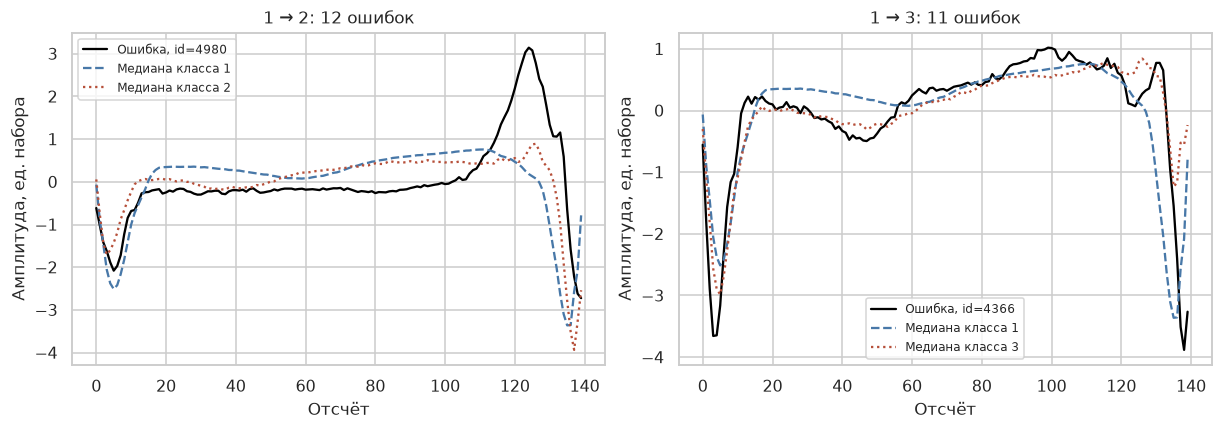

Частые ошибки: 1→2: 12; 1→3: 11; 3→1: 6


In [8]:
off_diagonal = cm.copy()
np.fill_diagonal(off_diagonal, 0)
pairs = sorted([(int(off_diagonal[a, b]), int(a), int(b))
                for a in CLASSES for b in CLASSES if a != b and off_diagonal[a, b] > 0], reverse=True)
if pairs:
    fig, axes = plt.subplots(1, min(2, len(pairs)), figsize=(11, 3.8), layout="constrained", squeeze=False)
    for ax, (count, true_class, predicted_class) in zip(axes.flat, pairs[:2]):
        mask = (y[test_idx] == true_class) & (test_result["predictions"] == predicted_class)
        row = test_idx[np.flatnonzero(mask)[0]]
        ax.plot(X[row], color="black", label=f"Ошибка, id={data.loc[row, 'heartbeat_id']}")
        ax.plot(class_medians[true_class], "--", color="#4878a8", label=f"Медиана класса {true_class}")
        ax.plot(class_medians[predicted_class], ":", color="#b64f39", label=f"Медиана класса {predicted_class}")
        ax.set(title=f"{true_class} → {predicted_class}: {count} ошибок",
               xlabel="Отсчёт", ylabel="Амплитуда, ед. набора")
        ax.legend(fontsize=8)
    save_figure("error_examples.png")
    print("Частые ошибки:", "; ".join(f"{a}→{b}: {n}" for n, a, b in pairs[:3]))

## Прогнозы для сдачи
Для внешнего CSV использовал те же веса и нормализацию. Сохранил модель
и параметры StandardScaler, чтобы прогноз можно было воспроизвести.
Дополнительно на валидации или тесте сеть не обучал.

In [9]:
external = pd.read_csv(external_path, usecols=["heartbeat_id", *FEATURES])
assert external["heartbeat_id"].is_unique
assert set(external["heartbeat_id"]).isdisjoint(data["heartbeat_id"])
external_X = scaler.transform(external[FEATURES].to_numpy(dtype=np.float32)).astype(np.float32)
assert np.isfinite(external_X).all()
model.eval()
with torch.inference_mode():
    external_predictions = np.concatenate([
        model(torch.from_numpy(batch[:, None, :])).argmax(dim=1).numpy()
        for batch in np.array_split(external_X, max(1, int(np.ceil(len(external_X) / BATCH_SIZE))))
    ])
submission = pd.DataFrame({"heartbeat_id": external["heartbeat_id"], "prediction": external_predictions})
assert submission.columns.tolist() == ["heartbeat_id", "prediction"]
assert submission["heartbeat_id"].equals(external["heartbeat_id"])
assert len(submission) == len(external) and not submission.isna().any().any()
assert set(submission["prediction"]) <= set(CLASSES)
submission.to_csv(ROOT / "outputs/task2_1_predictions.csv", index=False)
torch.save(model.state_dict(), OUT / "model.pt")
np.savez(OUT / "normalization.npz", mean=scaler.mean_, scale=scaler.scale_)
print(f"Сохранено {len(submission)} прогнозов в outputs/task2_1_predictions.csv.")
display(submission.head())

Сохранено 1000 прогнозов в outputs/task2_1_predictions.csv.


,heartbeat_id,prediction
0,2,0
1,5,0
2,12,0
3,17,0
4,20,0


## Выводы
Собрал результаты и ограничения в краткий отчёт. В исходном ECG5000
применялась автоматическая разметка, её ошибки здесь отдельно не проверялись.

In [10]:
common_errors = "; ".join(f"{a}→{b}: {n}" for n, a, b in pairs[:3]) or "ошибок нет"
weakest = per_class["f1-score"].idxmin()
report = (
    "Королев Даниил, 636-02. Задание 2.1.\n\n"
    f"В train.csv {len(data)} сокращений ЭКГ по 140 отсчётов, пять классов. "
    f"В классе 4 всего {counts[4]} примеров. Разделение 70/15/15 "
    f"({len(train_idx)}/{len(valid_idx)}/{len(test_idx)}) стратифицировано, seed=42. "
    "StandardScaler и веса классов n/(5*n_class) рассчитаны только на обучении. "
    "Идентификатор не используется как признак.\n\n"
    "1D CNN содержит три свёрточных блока (16/32/64 канала), ReLU, MaxPool, "
    "AdaptiveAvgPool, полносвязные слои и Dropout 0.2. Обучение: Adam, "
    "взвешенная CrossEntropy. По macro F1 валидации выбрана эпоха "
    f"{best_epoch} из {len(history)} выполненных, F1={best_f1:.3f}. "
    "Внутренний тест не использовался для выбора модели.\n\n"
    f"На внутреннем тесте Accuracy={test_result['accuracy']:.3f}, "
    f"macro F1={test_result['macro_f1']:.3f}. Частые ошибки: {common_errors}. "
    f"Самый слабый по F1 класс — {weakest} (F1={per_class.loc[weakest, 'f1-score']:.3f}). "
    "Крупные классы сильно влияют на Accuracy; macro F1 учитывает все классы поровну. "
    "Похожие формы сокращений и малое число редких примеров затрудняют различение; "
    "несколько ошибок заметно меняют их F1.\n\n"
    f"Для сдачи сохранено {len(submission)} прогнозов той же модели с исходными ID. "
    "Внешние метки и готовые ответы не читались. ECG5000 основан на одной записи; "
    "разделение сокращений не доказывает перенос на новых пациентов. "
    "Для улучшения нужны данные разных пациентов, проверка разметки и "
    "валидация по пациентам. Аугментации сигнала можно проверять только по "
    "валидации. Модель учебная и не предназначена для диагностики."
)
assert len(report) <= 2000, len(report)
_ = (ROOT / "your-sollution/task2_1_report.md").write_text(report + "\n", encoding="utf-8")
display(Markdown(report))
print(f"Отчёт: {len(report)} знаков с пробелами.")
metadata = {
    "author": "Королев Даниил", "group": "636-02", "seed": SEED, "device": "cpu",
    "train_rows": len(train_idx), "validation_rows": len(valid_idx), "internal_test_rows": len(test_idx),
    "external_rows": len(submission), "best_epoch": best_epoch, "epochs_run": len(history),
    "best_validation_macro_f1": best_f1,
    "internal_test_accuracy": test_result["accuracy"], "internal_test_macro_f1": test_result["macro_f1"],
    "confusion_matrix": cm.tolist(), "class_weights": class_weights.tolist(),
    "python": platform.python_version(), "torch": torch.__version__, "sklearn": sklearn.__version__,
    "source_sha256": {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in [train_path, external_path]},
    "predictions_sha256": hashlib.sha256((ROOT / "outputs/task2_1_predictions.csv").read_bytes()).hexdigest(),
}
_ = (OUT / "run_summary.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")

Королев Даниил, 636-02. Задание 2.1.

В train.csv 4000 сокращений ЭКГ по 140 отсчётов, пять классов. В классе 4 всего 19 примеров. Разделение 70/15/15 (2800/600/600) стратифицировано, seed=42. StandardScaler и веса классов n/(5*n_class) рассчитаны только на обучении. Идентификатор не используется как признак.

1D CNN содержит три свёрточных блока (16/32/64 канала), ReLU, MaxPool, AdaptiveAvgPool, полносвязные слои и Dropout 0.2. Обучение: Adam, взвешенная CrossEntropy. По macro F1 валидации выбрана эпоха 20 из 35 выполненных, F1=0.575. Внутренний тест не использовался для выбора модели.

На внутреннем тесте Accuracy=0.913, macro F1=0.582. Частые ошибки: 1→2: 12; 1→3: 11; 3→1: 6. Самый слабый по F1 класс — 4 (F1=0.000). Крупные классы сильно влияют на Accuracy; macro F1 учитывает все классы поровну. Похожие формы сокращений и малое число редких примеров затрудняют различение; несколько ошибок заметно меняют их F1.

Для сдачи сохранено 1000 прогнозов той же модели с исходными ID. Внешние метки и готовые ответы не читались. ECG5000 основан на одной записи; разделение сокращений не доказывает перенос на новых пациентов. Для улучшения нужны данные разных пациентов, проверка разметки и валидация по пациентам. Аугментации сигнала можно проверять только по валидации. Модель учебная и не предназначена для диагностики.

Отчёт: 1330 знаков с пробелами.
